In [2]:
import pandas as pd
rankdata = pd.read_csv('rankdata.csv')
rankdata.head()

,cpu_time,dataset_no,feature_name,feature_rank,ranking_method,dataset
0,1420.722823,1,A_0,8.0,RFE_XGBoost,"135_bit_mutliplexer [p=135,n=20000,h=1]"
1,1420.722823,1,A_1,20.0,RFE_XGBoost,"135_bit_mutliplexer [p=135,n=20000,h=1]"
2,1420.722823,1,A_2,23.0,RFE_XGBoost,"135_bit_mutliplexer [p=135,n=20000,h=1]"
3,1420.722823,1,A_3,35.0,RFE_XGBoost,"135_bit_mutliplexer [p=135,n=20000,h=1]"
4,1420.722823,1,A_4,11.0,RFE_XGBoost,"135_bit_mutliplexer [p=135,n=20000,h=1]"


In [4]:
datasets = pd.read_csv('rebate-datasets.csv')
datasets.head()

,theme,full_name,path,replica_no,replicas,p_predictive,p,n,heritability,edm,p_alternate,p_key
0,11_bit_mutliplexer,11_bit_mutliplexer,./rebate/11_bit_mutliplexer,1,30,11,11,1000,1,None,None,"A_0,A_1,A_2"
1,135_bit_mutliplexer,135_bit_mutliplexer,./rebate/135_bit_mutliplexer,1,30,135,135,20000,1,None,None,"A_0,A_1,A_2,A_3,A_4,A_5,A_6"
2,20_bit_mutliplexer,20_bit_mutliplexer,./rebate/20_bit_mutliplexer,1,30,20,20,2000,1,None,None,"A_0,A_1,A_2,A_3"
3,37_bit_mutliplexer,37_bit_mutliplexer,./rebate/37_bit_mutliplexer,1,30,37,37,5000,1,None,None,"A_0,A_1,A_2,A_3,A_4"
4,3 Class Balanced Data (2-way Epistasis+ME),3Class_Datasets_Loc_2,./rebate/3Class_Datasets_Loc_2,1,30,2,20,1600,1,Easy,None,"M0P0,M0P1"


In [78]:
import numpy as np
gt = datasets[datasets['full_name'] == '20_bit_mutliplexer']
p_key = gt.iloc[0].p_key.split(',')
rd = rankdata[rankdata['dataset'] == '20_bit_mutliplexer [p=20,n=2000,h=1]']
recall_scores = pd.DataFrame()
for ranking_method, data in rd.groupby('ranking_method'):
    print(ranking_method)
    for dataset_no, data in data.groupby('dataset_no'):
        for feature_rank, _ in data.groupby('feature_rank'):
            # print('validating subset with rank {}'.format(feature_rank))
            # construct subset- use all features up to this rank.
            subset = data[data['feature_rank'] <= feature_rank]
            # print(len(subset.index))
            positives = subset['feature_name'].values
            n_positives = len(positives)
            n_true_positives = np.sum(np.isin(positives, p_key))
            n_false_positives = n_positives - n_true_positives
            n_false_negatives = len(p_key) - n_true_positives
            recall = n_true_positives / len(p_key)
            precision = n_true_positives / n_positives
            # print(positives)
            # print('positives: {}/{}'.format(n_true_positives, n_positives))
            # print('negatives: identified {} as negative falsely'.format(n_false_negatives))
            # print('recall = {}, precision = {}'.format(recall, precision))
            # print(subset)
            recall_score = pd.DataFrame(data={
                'recall': recall,
                'feature_rank': feature_rank,
                'dataset_no': dataset_no,
                'ranking_method': ranking_method,
                'n_features': n_positives
            }, index=[len(recall_scores.index)])
            recall_scores = recall_scores.append(recall_score)
        # break
    # break
recall_scores.head()

FeatBoost_XGBoost
RFE_XGBoost


,recall,feature_rank,dataset_no,ranking_method,n_features
0,0.25,1.0,1,FeatBoost_XGBoost,1
1,0.50,2.0,1,FeatBoost_XGBoost,2
2,0.75,3.0,1,FeatBoost_XGBoost,3
3,1.00,4.0,1,FeatBoost_XGBoost,4
4,1.00,5.0,1,FeatBoost_XGBoost,5


Text(0.5, 1.0, 'recall per ranking method')

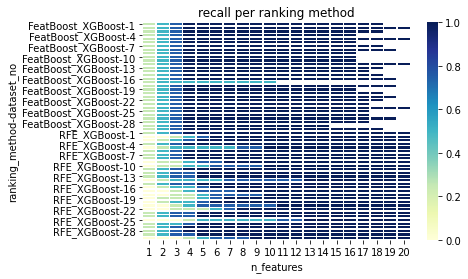

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt
rectangular = pd.pivot_table(recall_scores, values='recall', index=['ranking_method', 'dataset_no'], columns=['n_features'])
g = sns.heatmap(rectangular, linewidths=.5, cmap="YlGnBu", yticklabels=3)
plt.title('recall per ranking method')